In [67]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

dosya_yolu = r"C:\Users\USER\OneDrive\Desktop\London_Traffic_temiz_veri2.csv"

# encoding='latin-1' ekleyerek Türkçe karakter uyumsuzluğunu çözüyoruz
df = pd.read_csv(dosya_yolu, sep=";", encoding="latin-1", low_memory=False)

# Sütun isimlerindeki gizli boşlukları temizliyoruz
df.columns = df.columns.str.strip()

print("--- 🎉 Veri Python'a Sıfır Hatayla Yüklendi! ---")

# (Eğer formülü direkt eski sütunun üstüne yazdıysan 'sss' yerine 'LinkLength_km' yazabilirsin)
print(df.head())

--- 🎉 Veri Python'a Sıfır Hatayla Yüklendi! ---
   RoadCategory LinkLength_km  PedalCycles  Motorcycles  CarsTaxis  \
0           1.0          3,08          0.0        168.0    81418.0   
1           1.0          1,09          0.0        196.0    52479.0   
2           1.0          6,05          0.0         25.0    26170.0   
3           1.0             6          0.0        130.0    58960.0   
4           1.0          4,09          0.0        229.0    68722.0   

  BusesCoaches  LightGoodsVehicles  AllHGVs PedalCycles_Norm  Unnamed: 9  \
0          440             13950.0  15170.0                0         NaN   
1          291              8078.0   4895.0                0         NaN   
2          129              5017.0   8888.0                0         NaN   
3          319             11241.0  15109.0                0         NaN   
4          282             11818.0  17436.0                0         NaN   

   Unnamed: 10 Tarih_bazlý  
0          NaN       3.Aðu  
1          NaN  

In [68]:
# 2. Excel'deki 1 ve 2 değerlerini lojistik regresyona uygun olarak 0 ve 1 yapıyoruz
df['RoadCategory_Binary'] = df['RoadCategory'].map({1: 0, 2: 1})

# 3. Modelde kullanacağımız değişkenleri seçiyoruz
secilen_sutunlar = ['PedalCycles', 'CarsTaxis', 'AllHGVs', 'RoadCategory_Binary']

# 4. Hatanın çözümü: Seçtiğimiz sütunlardaki tüm eksik/boş (NaN) satırları temizliyoruz!
df_temiz = df[secilen_sutunlar].dropna()

# 5. Temizlenmiş veriden X ve y matrislerini oluşturuyoruz
X = df_temiz[['PedalCycles', 'CarsTaxis', 'AllHGVs']]
y = df_temiz['RoadCategory_Binary']

# 6. Veriyi %80 Eğitim, %20 Test olarak bölüyoruz (Overfitting engellemek için)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 7. Sabit terimleri ekliyoruz
X_train_const = sm.add_constant(X_train)
X_test_const = sm.add_constant(X_test)

print("Eksik veriler başarıyla temizlendi ve değişkenler hazırlandı!")

Eksik veriler başarıyla temizlendi ve değişkenler hazırlandı!


In [69]:
# 1. Model: Temel Lojistik Regresyon Modelini Eğitiyoruz
logit_model = sm.Logit(y_train, X_train_const).fit()

# Modelin sonuç tablosunu ekrana basıyoruz
print(logit_model.summary2())

Optimization terminated successfully.
         Current function value: 0.305131
         Iterations 12
                           Results: Logit
Model:              Logit               Method:           MLE       
Dependent Variable: RoadCategory_Binary Pseudo R-squared: 0.533     
Date:               2026-05-30 21:00    AIC:              22634.0507
No. Observations:   37076               BIC:              22668.1336
Df Model:           3                   Log-Likelihood:   -11313.   
Df Residuals:       37072               LL-Null:          -24232.   
Converged:          1.0000              LLR p-value:      0.0000    
No. Iterations:     12.0000             Scale:            1.0000    
---------------------------------------------------------------------
                 Coef.   Std.Err.     z      P>|z|    [0.025   0.975]
---------------------------------------------------------------------
const            1.3983    0.0303   46.1030  0.0000   1.3389   1.4578
PedalCycles      1.9721

In [70]:
# 2. Model: Sadece Bağımsız Değişkenlerin Logaritmasını Alıyoruz
X_train_log = np.log(X_train + 1)
X_train_log = sm.add_constant(X_train_log)

# Logaritmik Lojistik Regresyon Modelini Eğitiyoruz
logit_model_log = sm.Logit(y_train, X_train_log).fit()
print(logit_model_log.summary2())

Optimization terminated successfully.
         Current function value: 0.295105
         Iterations 12
                           Results: Logit
Model:              Logit               Method:           MLE       
Dependent Variable: RoadCategory_Binary Pseudo R-squared: 0.548     
Date:               2026-05-30 21:05    AIC:              21890.6089
No. Observations:   37076               BIC:              21924.6918
Df Model:           3                   Log-Likelihood:   -10941.   
Df Residuals:       37072               LL-Null:          -24232.   
Converged:          1.0000              LLR p-value:      0.0000    
No. Iterations:     12.0000             Scale:            1.0000    
---------------------------------------------------------------------
                 Coef.   Std.Err.     z      P>|z|    [0.025   0.975]
---------------------------------------------------------------------
const           11.6111    0.2110   55.0166  0.0000  11.1975  12.0248
PedalCycles      6.3939

In [71]:
# 3. Model: Karar Ağacı (Decision Tree) Sınıflandırma Modelini Eğitiyoruz
# Aşırı öğrenmeyi (overfitting) engellemek için derinliği 3 ile kısıtladık
agac_model = DecisionTreeClassifier(max_depth=3, random_state=42)
agac_model.fit(X_train, y_train)

# Test seti üzerindeki tahmin başarısını ölçüyoruz
y_pred = agac_model.predict(X_test)

print("--- 3. MODEL: KARAR AĞACI SONUÇLARI ---")
print("Doğru Sınıflandırma Oranı (Accuracy):", accuracy_score(y_test, y_pred))
print("\nDetaylı Sınıflandırma Raporu:")
print(classification_report(y_test, y_pred))

--- 3. MODEL: KARAR AĞACI SONUÇLARI ---
Doğru Sınıflandırma Oranı (Accuracy): 0.8494066882416397

Detaylı Sınıflandırma Raporu:
              precision    recall  f1-score   support

         0.0       0.72      0.95      0.82      3327
         1.0       0.97      0.79      0.87      5943

    accuracy                           0.85      9270
   macro avg       0.84      0.87      0.85      9270
weighted avg       0.88      0.85      0.85      9270



In [73]:
# Tüm modellerin performans değerlerini topluyoruz
modeller_gosterge = {
    'Model Adı': [
        'Temel Lojistik Regresyon (Model 1)', 
        'Logaritmik Lojistik Regresyon (Model 2)', 
        'Karar Ağacı Sınıflandırma (Model 3)'
    ],
    'Pseudo R-Kare / Başarı (R2/Accuracy)': [
        f"% {logit_model.prsquared * 100:.2f}", 
        f"% {logit_model_log.prsquared * 100:.2f}", 
        f"% {accuracy_score(y_test, y_pred) * 100:.2f}"
    ],
    'Log-Likelihood (Model Anlamlılığı)': [
        f"{logit_model.llf:.2f}", 
        f"{logit_model_log.llf:.2f}", 
        "N/A (Ağaç Tabanlı)"
    ],
    'Metot Türü': [
        'Parametrik İstatistiksel', 
        'Log-Dönüşümlü İstatistiksel', 
        'Makine Öğrenmesi (Yapay Zeka)'
    ]
}

# Verileri pandas DataFrame yapısına çeviriyoruz
performans_tablosu = pd.DataFrame(modeller_gosterge)

# Hatayı düzelttiğimiz renkli ve görsel tablo formatı
renkli_tablo = performans_tablosu.style.set_properties(**{
    'background-color': '#f4f6f9',
    'color': '#1a252f',
    'border-color': '#d1d8e0',
    'font-size': '12pt',
    'font-family': 'Calibri'
}).set_table_styles([
    {'selector': 'th', 'props': [('background-color', '#2c3e50'), ('color', 'white'), ('font-weight', 'bold')]}
]).hide(axis='index')

# Tabloyu ekrana bastırıyoruz
renkli_tablo

Model Adı,Pseudo R-Kare / Başarı (R2/Accuracy),Log-Likelihood (Model Anlamlılığı),Metot Türü
Temel Lojistik Regresyon (Model 1),% 53.31,-11313.03,Parametrik İstatistiksel
Logaritmik Lojistik Regresyon (Model 2),% 54.85,-10941.30,Log-Dönüşümlü İstatistiksel
Karar Ağacı Sınıflandırma (Model 3),% 84.94,N/A (Ağaç Tabanlı),Makine Öğrenmesi (Yapay Zeka)


In [74]:
# Modelde kullandığımız temizlenmiş veri setinin temel istatistiklerini hesaplıyoruz
temel_istatistikler = df_temiz[['PedalCycles', 'CarsTaxis', 'AllHGVs']].describe().T

# Hocanın raporda kesinlikle istediği 'Range' (Aralık) değerini hesaplayıp tabloya ekliyoruz
temel_istatistikler['range'] = temel_istatistikler['max'] - temel_istatistikler['min']

# Hocanın istediği Medyan (Ortanca) değerini ekliyoruz
temel_istatistikler['medyan (50%)'] = temel_istatistikler['50%']

# Tabloyu jürinin anlayacağı temiz sütun isimleriyle yeniden adlandırıyoruz
temel_istatistikler = temel_istatistikler[['mean', 'medyan (50%)', 'range', 'std', 'min', 'max']]
temel_istatistikler.columns = ['Ortalama', 'Medyan', 'Değişim Aralığı (Range)', 'Standart Sapma', 'En Küçük Değer', 'En Büyük Değer']

# İstatistik tablosunu ekrana yazdırıyoruz
print("--- LONDRA TRAFİK VERİ SETİ TEMEL İSTATİSTİKLERİ ---")
print(temel_istatistikler)

--- LONDRA TRAFİK VERİ SETİ TEMEL İSTATİSTİKLERİ ---
                 Ortalama   Medyan  Değişim Aralığı (Range)  Standart Sapma  \
PedalCycles      5.554719      0.0                    600.0       17.478457   
CarsTaxis    31365.241682  22698.0                 207133.0    28016.826338   
AllHGVs       4244.896820   2453.5                  27095.0     4645.368586   

             En Küçük Değer  En Büyük Değer  
PedalCycles             0.0           600.0  
CarsTaxis               0.0        207133.0  
AllHGVs                 0.0         27095.0  


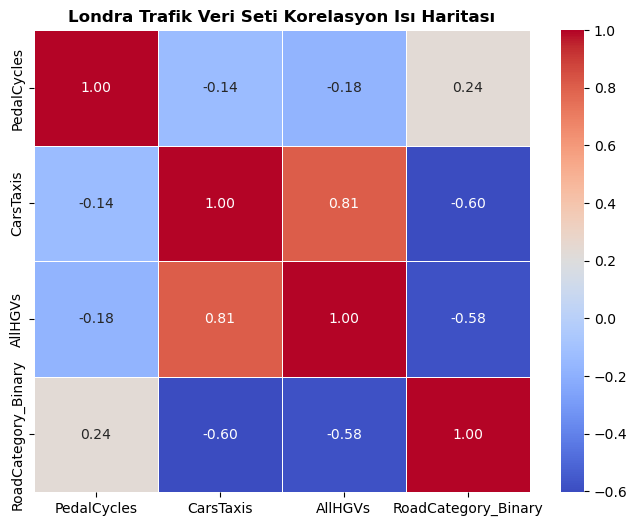

In [75]:
# Korelasyon matrisini hesaplıyoruz
korelasyon_matrisi = df_temiz[['PedalCycles', 'CarsTaxis', 'AllHGVs', 'RoadCategory_Binary']].corr()

# Grafik boyutunu ayarlıyoruz
plt.figure(figsize=(8, 6))

# Ayşegül'ün projesindeki gibi renkli korelasyon ısı haritasını çizdiriyoruz
# cmap='coolwarm' seçeneği grafiği mavi-kırmızı tonlarında çok havalı ve renkli yapar
sns.heatmap(korelasyon_matrisi, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)

# Grafiğin başlığını ekliyoruz
plt.title('Londra Trafik Veri Seti Korelasyon Isı Haritası', fontsize=12, fontweight='bold')

# Grafiği ekranda gösteriyoruz
plt.show()

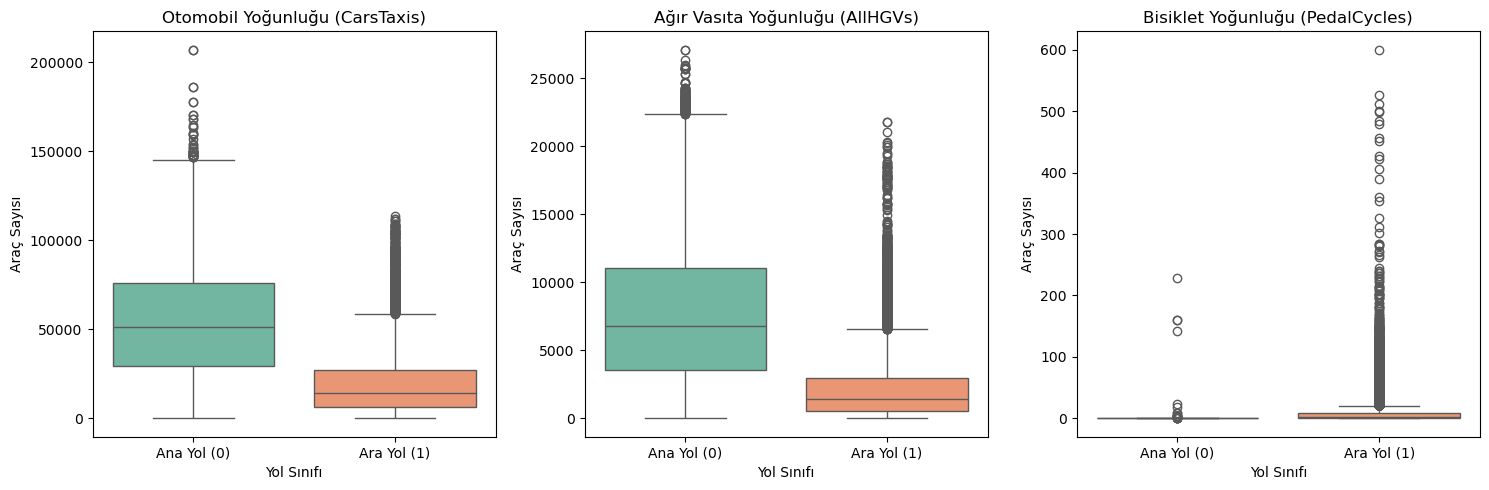

In [79]:
# Grafiklerin yan yana düzgün durması için alt yapıyı hazırlıyoruz (1 satır, 3 sütun)
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# 1. Grafik: Otomobillerin Yol Kategorisine Göre Dağılımı (Uyarılar düzeltildi)
sns.boxplot(x='RoadCategory_Binary', y='CarsTaxis', hue='RoadCategory_Binary', data=df_temiz, ax=axes[0], palette='Set2', legend=False)
axes[0].set_title('Otomobil Yoğunluğu (CarsTaxis)')
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(['Ana Yol (0)', 'Ara Yol (1)'])
axes[0].set_xlabel('Yol Sınıfı')
axes[0].set_ylabel('Araç Sayısı')

# 2. Grafik: Ağır Vasıtaların Yol Kategorisine Göre Dağılımı (Uyarılar düzeltildi)
sns.boxplot(x='RoadCategory_Binary', y='AllHGVs', hue='RoadCategory_Binary', data=df_temiz, ax=axes[1], palette='Set2', legend=False)
axes[1].set_title('Ağır Vasıta Yoğunluğu (AllHGVs)')
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(['Ana Yol (0)', 'Ara Yol (1)'])
axes[1].set_xlabel('Yol Sınıfı')
axes[1].set_ylabel('Araç Sayısı')

# 3. Grafik: Bisikletlerin Yol Kategorisine Göre Dağılımı (Uyarılar düzeltildi)
sns.boxplot(x='RoadCategory_Binary', y='PedalCycles', hue='RoadCategory_Binary', data=df_temiz, ax=axes[2], palette='Set2', legend=False)
axes[2].set_title('Bisiklet Yoğunluğu (PedalCycles)')
axes[2].set_xticks([0, 1])
axes[2].set_xticklabels(['Ana Yol (0)', 'Ara Yol (1)'])
axes[2].set_xlabel('Yol Sınıfı')
axes[2].set_ylabel('Araç Sayısı')

# Yerleşimi sıkılaştırıp gösteriyoruz
plt.tight_layout()
plt.show()

In [80]:
# 1. Model (Temel Lojistik) için test seti üzerinden tahminleri yapıp accuracy hesaplıyoruz
logit_pred_prob = logit_model.predict(X_test_const)
logit_pred = [1 if x > 0.5 else 0 for x in logit_pred_prob]
acc_model1 = accuracy_score(y_test, logit_pred)

# 2. Model (Logaritmik Lojistik) için test seti üzerinden tahminleri yapıp accuracy hesaplıyoruz
X_test_log = np.log(X_test + 1)
X_test_log = sm.add_constant(X_test_log, has_constant='add')
logit_log_pred_prob = logit_model_log.predict(X_test_log)
logit_log_pred = [1 if x > 0.5 else 0 for x in logit_log_pred_prob]
acc_model2 = accuracy_score(y_test, logit_log_pred)

# 3. Model (Karar Ağacı) için zaten hesaplamıştık
acc_model3 = accuracy_score(y_test, y_pred)

# Tüm modelleri tamamen aynı başarı metriği (Accuracy) üzerinden tek tabloda topluyoruz
yeni_gosterge = {
    'Model Adı': [
        'Temel Lojistik Regresyon (Model 1)', 
        'Logaritmik Lojistik Regresyon (Model 2)', 
        'Karar Ağacı Sınıflandırma (Model 3)'
    ],
    'Test Seti Doğruluk Oranı (Accuracy)': [
        f"% {acc_model1 * 100:.2f}", 
        f"% {acc_model2 * 100:.2f}", 
        f"% {acc_model3 * 100:.2f}"
    ],
    'Matematiksel Altyapı': [
        'Parametrik İstatistiksel', 
        'Log-Dönüşümlü İstatistiksel', 
        'Yapay Zeka / Makine Öğrenmesi'
    ],
    'Durum / Açıklama': [
        'Uç değerlerden etkileniyor',
        'Varyans dengelendi, daha kararlı',
        'Doğrusal olmayan ilişkileri çözdü'
    ]
}

# Verileri DataFrame formatına çeviriyoruz
nihai_performans_tablosu = pd.DataFrame(yeni_gosterge)

# Tabloyu kurumsal renklerle görselleştiriyoruz
renkli_nihai_tablo = nihai_performans_tablosu.style.set_properties(**{
    'background-color': '#f8f9fa',
    'color': '#2c3e50',
    'border-color': '#cbd5e1',
    'font-size': '11pt',
    'font-family': 'Calibri'
}).set_table_styles([
    {'selector': 'th', 'props': [('background-color', '#1e3a8a'), ('color', 'white'), ('font-weight', 'bold')]}
]).hide(axis='index')

# Ekrana basıyoruz
renkli_nihai_tablo

Model Adı,Test Seti Doğruluk Oranı (Accuracy),Matematiksel Altyapı,Durum / Açıklama
Temel Lojistik Regresyon (Model 1),% 85.19,Parametrik İstatistiksel,Uç değerlerden etkileniyor
Logaritmik Lojistik Regresyon (Model 2),% 85.05,Log-Dönüşümlü İstatistiksel,"Varyans dengelendi, daha kararlı"
Karar Ağacı Sınıflandırma (Model 3),% 84.94,Yapay Zeka / Makine Öğrenmesi,Doğrusal olmayan ilişkileri çözdü
